In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import scipy.sparse as sps
import jlinops

from solvers import GKSIAS
from psolvers import PGKSIAS
from rsolvers import RIASGKS

# Setup toy problem

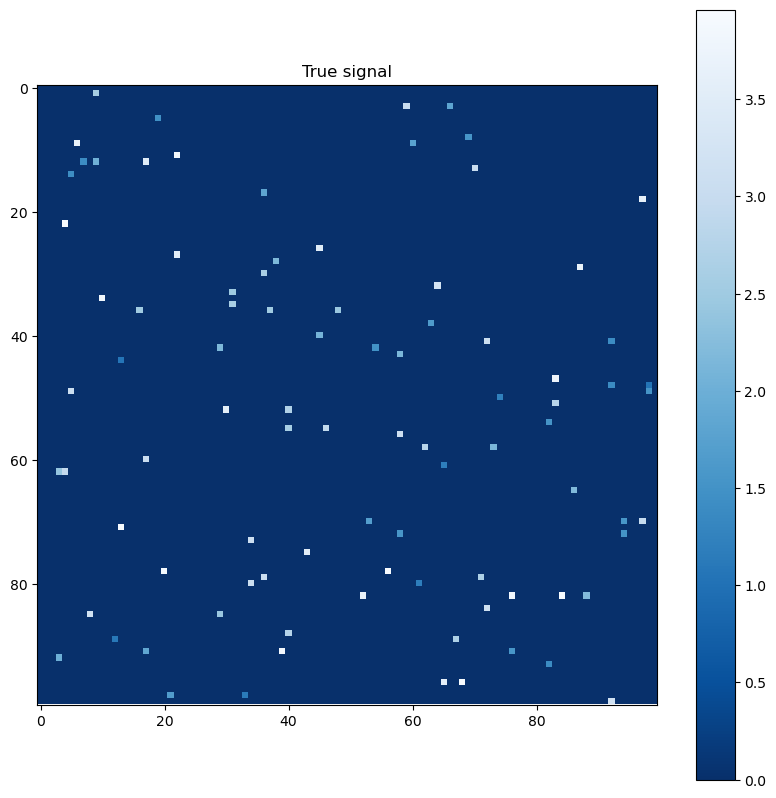

In [2]:
# Set example size
M, N = 100, 100
img_shape = (M,N)

# Draw random image
np.random.seed(1)
p = np.random.binomial(1, 0.01, size=img_shape).astype(np.float64)
q = np.random.uniform(low=1, high=4, size=img_shape).astype(np.float64)
image = p*q

plt.figure(figsize=(10,10))
plt.imshow(image, cmap="Blues_r")
plt.title("True signal")
plt.colorbar()
plt.show()

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_77235/3620108878.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


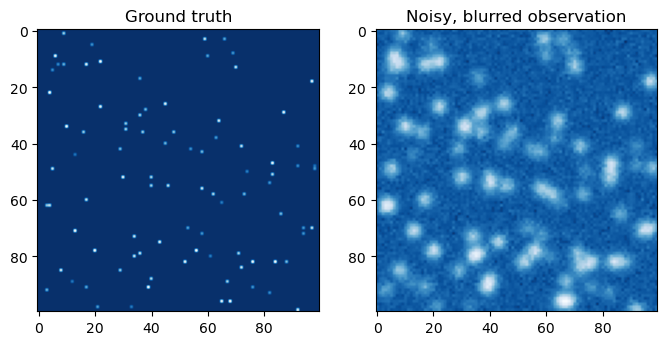

In [11]:

# Make blurring operator
blur_sigma = np.array(2.0).astype(np.float64) # standard deviation of the blur
A = jlinops.Gaussian2DBlurOperator(image.shape, blur_sigma=2, mode="constant")

# Blurred image
blurred_image = A.matvec_shaped(image)

# Add some noise
noise_stdev = 0.01
noise_var = noise_stdev**2
noisy_image = blurred_image + noise_stdev*np.random.normal(size=image.shape)

# Plot
fig, axs = plt.subplots(1, 2, figsize=(8,5))
axs[0].imshow(image, cmap="Blues_r")
axs[0].set_title("Ground truth")
axs[1].imshow(noisy_image, cmap="Blues_r")
axs[1].set_title("Noisy, blurred observation")
fig.show()

# Define regularization

In [12]:
#L = jlinops.Neumann2D(image.shape)
L = jlinops.IdentityOperator((M*N, M*N))

# Set parameters

In [18]:
n_iters = 65
# hyperpr_r = 1
# hyperpr_beta = 1.5 + 1e-3

hyperpr_r = -1.0
hyperpr_beta = 1.0

# IAS solve

In [19]:
# Set method
method = "dp2"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

# _Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
# Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

# W = jlinops.MatrixLinearOperator(Wmat)


Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*noisy_image.flatten()

err_norm_sq = len(noisy_image.flatten()) # in expectation

# Build solver
ias_solver = GKSIAS(A, L, noisy_image.flatten(), noise_var=noise_var)

# Run the solver
ias_data = ias_solver.solve(n_iter=n_iters, init_dim=8, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=image.flatten(), regparam=method, regparam_fixed=1e3)


# 

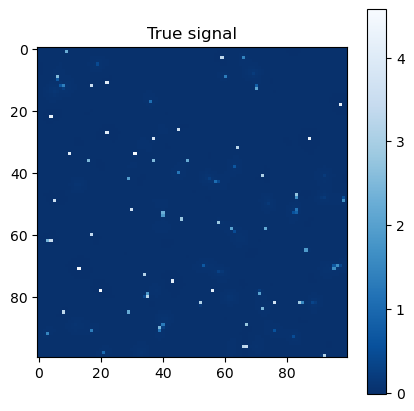

In [20]:
plt.figure(figsize=(5,5))
plt.imshow(ias_data["x"].reshape((M,N)), cmap="Blues_r")
plt.title("True signal")
plt.colorbar()
plt.show()

In [21]:
# Set method
method = "dp2"

Lpinv_factory = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = None

Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*noisy_image.flatten()

err_norm_sq = len(noisy_image.flatten()) # in expectation

pias_data = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=5, n_iter=n_iters, regparam=method, x_true=image.flatten(), x0=None, shift_scale=1.0, regparam_fixed=1e0,
                           err_norm_sq=err_norm_sq)

running MMGKS...: 100%|██████████| 65/65 [00:28<00:00,  2.27it/s]


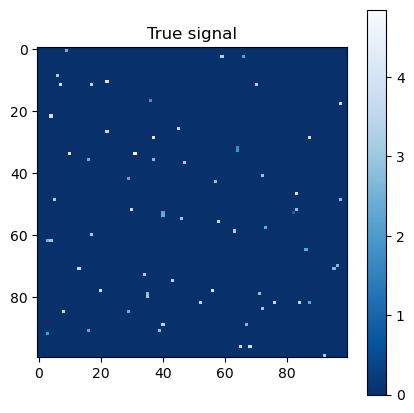

In [22]:
plt.figure(figsize=(5,5))
plt.imshow(pias_data[0].reshape((M,N)), cmap="Blues_r")
plt.title("True signal")
plt.colorbar()
plt.show()

# RIAS

In [23]:
n_iters = 1000
kmin = 15
kmax = 30

# Set method
method = "dp2"

Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*noisy_image.flatten()

err_norm_sq = len(noisy_image.flatten()) # in expectation

rias_solver = RIASGKS(A, L, noisy_image.flatten(), noise_var=noise_var)

rias_data = rias_solver.solve(n_iter=n_iters, kmin=kmin, kmax=kmax, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=image.flatten(), regparam=method, regparam_fixed=1e0)

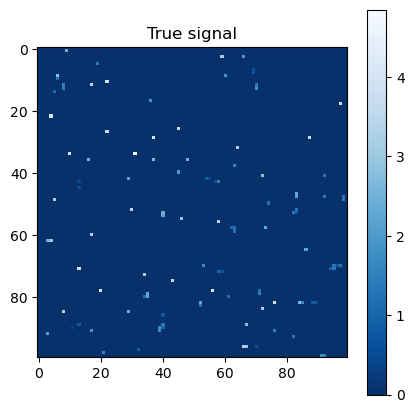

In [24]:
plt.figure(figsize=(5,5))
plt.imshow(rias_data["x"].reshape((M,N)), cmap="Blues_r")
plt.title("True signal")
plt.colorbar()
plt.show()

# Comparison

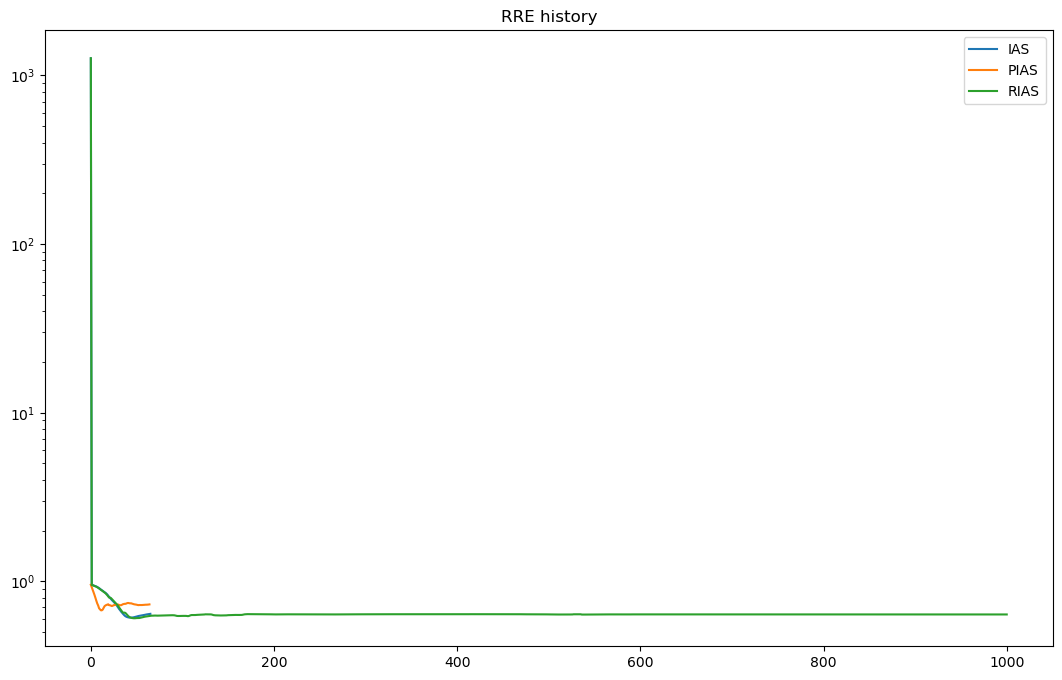

In [27]:
plt.figure(figsize=(13,8))

plt.semilogy(ias_data["rre_history"], label="IAS")
plt.semilogy(pias_data[1]["relError"], label="PIAS")
plt.semilogy(rias_data["rre_history"], label="RIAS")

plt.legend(loc="upper right")
plt.title("RRE history")
# plt.ylim(1e-2, 1e-0)
plt.show()

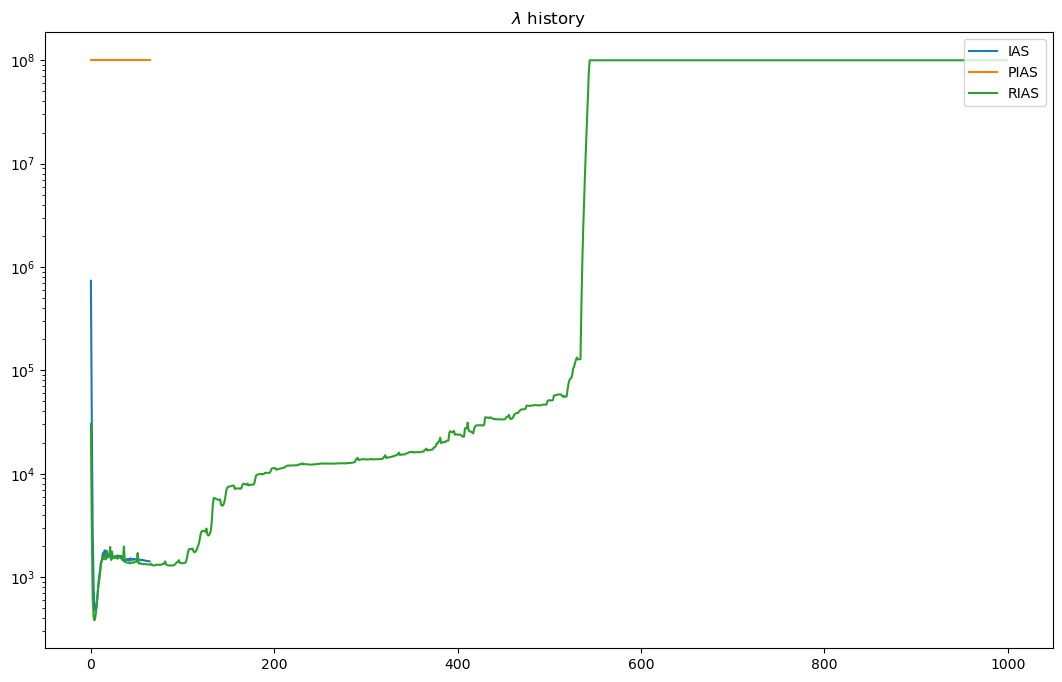

In [28]:
plt.figure(figsize=(13,8))

plt.semilogy(ias_data["lambda_history"], label="IAS")
plt.semilogy(pias_data[1]["regParam_history"], label="PIAS")
plt.semilogy(rias_data["lambda_history"], label="RIAS")

plt.legend(loc="upper right")
plt.title("$\\lambda$ history")
plt.show()

# First couple basis vectors?

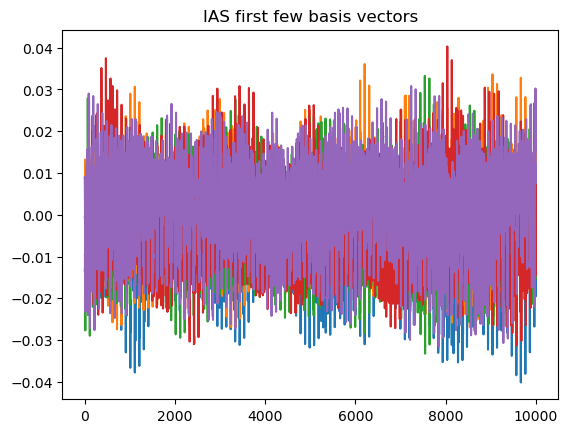

In [14]:
for j in range(5):
    plt.plot(ias_data["V"][:,j] )
plt.title("IAS first few basis vectors")
plt.show()

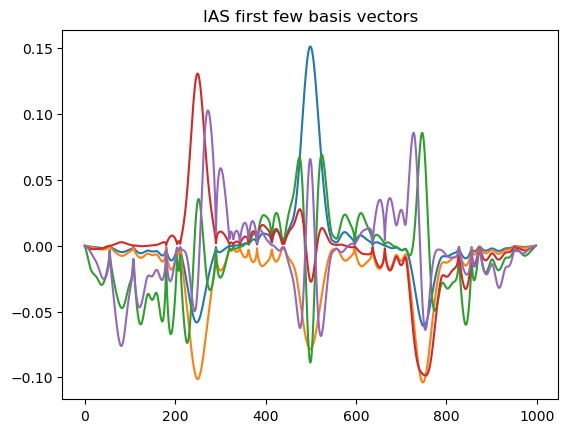

In [40]:
for j in range(5):
    plt.plot(pias_data[1]["V"][:,j] )
plt.title("PIAS first few basis vectors")
plt.show()

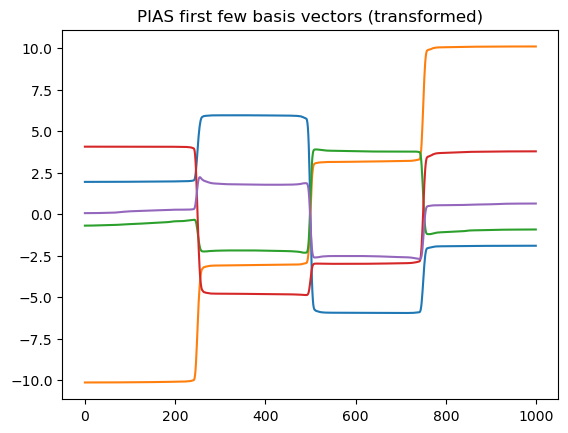

In [41]:
for j in range(5):
    plt.plot(pias_data[1]["LopinvV"][:,j] )
plt.title("PIAS first few basis vectors (transformed)")
plt.show()

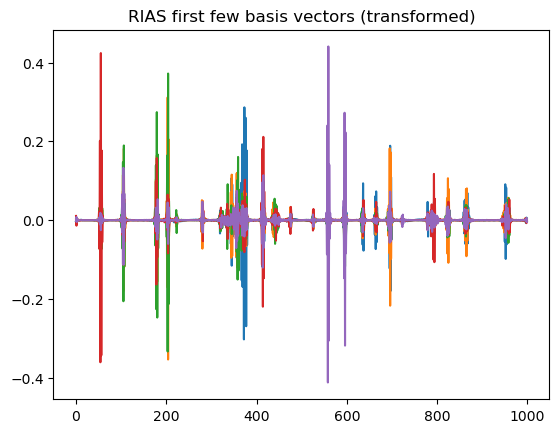

In [43]:
for j in range(5):
    plt.plot(rias_data["V"][:,j] )
plt.title("RIAS first few basis vectors (transformed)")
plt.show()